# Class 11: Feature Engineering, Feature Selection and RandomizedSearchCV
Predicting a car's fuel economy (`mpg`) from the Auto MPG dataset. Workflow: baseline, feature engineering, feature importance, feature selection, RandomizedSearchCV, one final test evaluation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import sklearn
from sklearn.model_selection import train_test_split, KFold, cross_validate, RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from sklearn.dummy import DummyRegressor

In [2]:
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.9.1


## Part 1 — Load and Understand the Dataset

In [3]:
DATA_FILE = "auto-mpg.csv"
DATA_URL = "https://raw.githubusercontent.com/plotly/datasets/master/auto-mpg.csv"

# Use the local copy next to the notebook (VS Code). In Colab, download it instead.
data_source = DATA_FILE if Path(DATA_FILE).exists() else DATA_URL
df = pd.read_csv(data_source)
df = df.rename(columns={"model-year": "model_year"})

print("Loaded from:", data_source)
print("Shape:", df.shape)
print("Columns:", list(df.columns))

Loaded from: auto-mpg.csv
Shape: (398, 7)
Columns: ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year']


In [4]:
df.head(10)

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
0,18.0,8,307.0,130.0,3504,12.0,70
1,15.0,8,350.0,165.0,3693,11.5,70
2,18.0,8,318.0,150.0,3436,11.0,70
3,16.0,8,304.0,150.0,3433,12.0,70
4,17.0,8,302.0,140.0,3449,10.5,70
5,15.0,8,429.0,198.0,4341,10.0,70
6,14.0,8,454.0,220.0,4354,9.0,70
7,14.0,8,440.0,215.0,4312,8.5,70
8,14.0,8,455.0,225.0,4425,10.0,70
9,15.0,8,390.0,190.0,3850,8.5,70


In [5]:
# Every column loads as a number, so no text-to-number conversion is needed.
# This version of the dataset has no car name column.
df.dtypes

mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight            int64
acceleration    float64
model_year        int64
dtype: object

In [6]:
df.isna().sum()

mpg             0
cylinders       0
displacement    0
horsepower      2
weight          0
acceleration    0
model_year      0
dtype: int64

In [7]:
df.describe()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.000000,398.000000,398.000000,396.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.189394,2970.424623,15.568090,76.010050
std,7.815984,1.701004,104.269838,38.402030,846.841774,2.757689,3.697627
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000
50%,23.000000,4.000000,148.500000,92.000000,2803.500000,15.500000,76.000000
75%,29.000000,8.000000,262.000000,125.000000,3608.000000,17.175000,79.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000


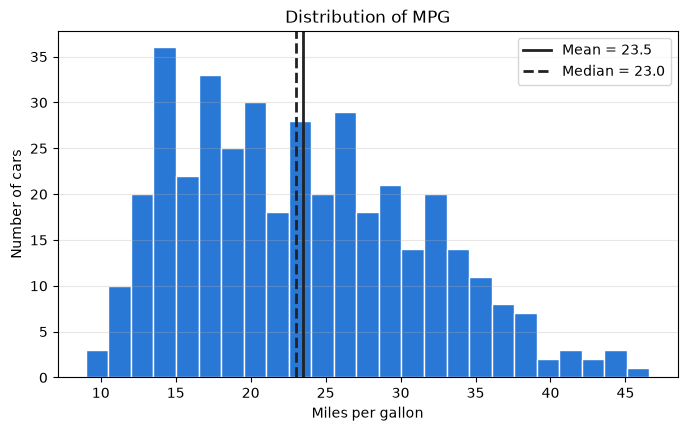

In [8]:
mpg_mean = df["mpg"].mean()
mpg_median = df["mpg"].median()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(df["mpg"], bins=25, color="#2a78d6", edgecolor="white")
ax.axvline(mpg_mean, color="#222222", linewidth=2, label=f"Mean = {mpg_mean:.1f}")
ax.axvline(mpg_median, color="#222222", linewidth=2, linestyle="--", label=f"Median = {mpg_median:.1f}")
ax.set_title("Distribution of MPG")
ax.set_xlabel("Miles per gallon")
ax.set_ylabel("Number of cars")
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.show()

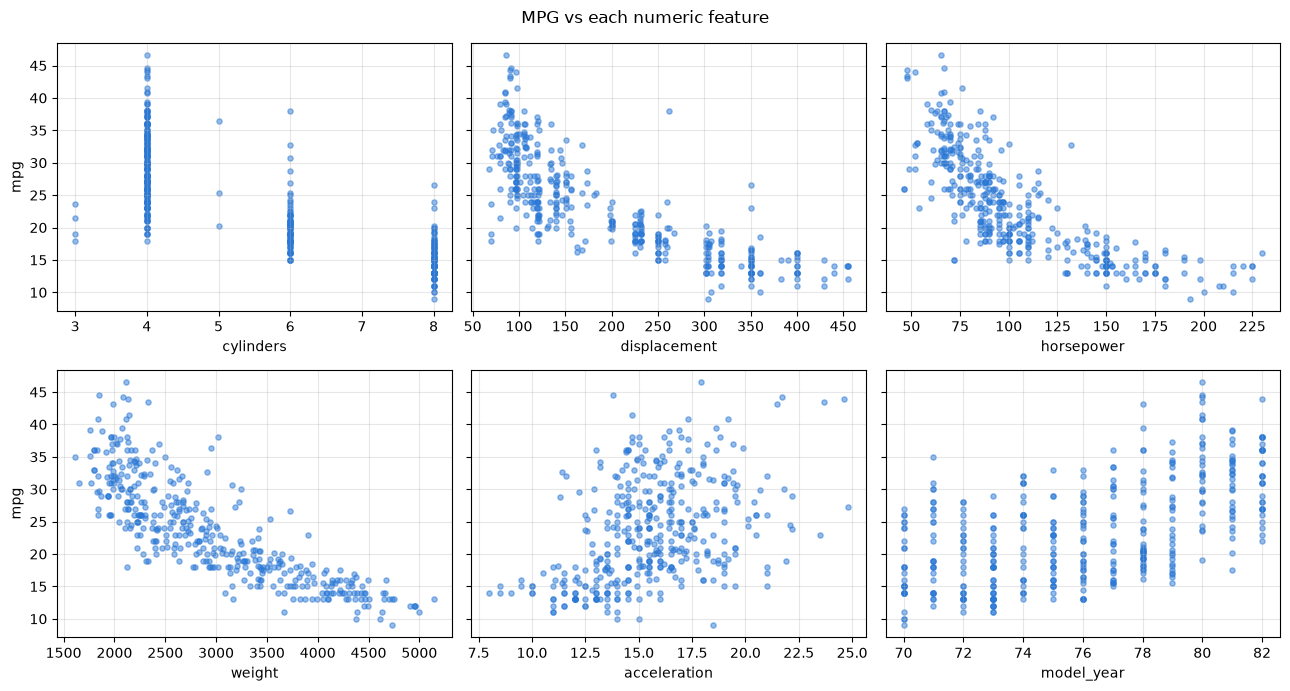

In [9]:
original_features = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]

fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharey=True)
for ax, feature in zip(axes.flat, original_features):
    ax.scatter(df[feature], df["mpg"], s=14, alpha=0.5, color="#2a78d6")
    ax.set_xlabel(feature)
    ax.grid(alpha=0.3)
for ax in axes[:, 0]:
    ax.set_ylabel("mpg")
fig.suptitle("MPG vs each numeric feature")
fig.tight_layout()
plt.show()

### Part 1 Questions

**1. What does one row represent?**

**My answer:**

**2. What is the prediction target?**

**My answer:**

**3. Why is this a regression problem?**

**My answer:**

**4. Which columns could potentially be useful predictors?**

**My answer:**

**5. Which columns contain missing values?**

**My answer:**